This activity assumes that you already completed the simpler bar chart activity.

We want to compose bar charts with colored bars and axis labels, like the following:

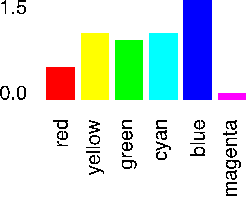

Let's decompose the graphic, so that we can create a bunch of functions that create the different parts.

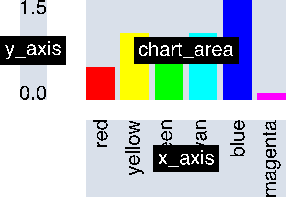

There is a horizontal gap between the `y_axis` and the `chart_area`, and a vertical gap between the `x_axis` and the `chart_area`.

The `chart_area` is very similar to the bar chart from the simpler bar chart activity. The only difference is that the bars also have different colors.

The `y_axis` is rather simple: it has the same height as the `chart_area`, and it has a text at its top and a text aligned at its bottom.

The `x_axis` consists of rotated texts, centered below each bar.

### Gaps

We need gaps between the different parts of the chart (and between bars).

Let's implement two functions to create gaps: `hgap` to create a horizontal gap of a given width, and `vgap` to create a vertical gap with a given height. To crete a horizontal gap, we can create a <API>rectangle</API> with that width and with a height of 0 (vice versa for a vertical gap). While we have to specify the color of the rectangle, the color we pick does not really matter, because the rectangle has an area of 0 and thus is invisible.

In [42]:
from pytamaro import Graphic, rectangle, black

def hgap(gap_width: float) -> Graphic:
    return rectangle(gap_width, 0, black)

def vgap(gap_height: float) -> Graphic:
    return rectangle(0, gap_height, black)


### A Single Bar
A bar chart consists of bars that are placed next to each other.
Different bars in the same chart have different **heights** and different **colors**.
To determine the height of a bar, we need to take into account:

* the amount of space we have for the complete chart (specifically, the `chart_height`)
* the value represented by this specific bar (`value`)
* the maximum value to be shown in the chart (`max_value`), which will be represented by the tallest bar, which will take up the entire `chart_height`

Compute the `bar_height`, and then construct a <API>rectangle</API> with the necessary dimensions and the given color.

In [ ]:
from pytamaro import Color, red, show_graphic

def bar(bar_width: float, value: float, max_value: float, chart_height: float, color: Color) -> Graphic:
    bar_height = # TODO
    return # TODO

# Show a bar with a width of 60, that would fits into a chart with an overall height of 200, 
# and that represents the value of 5.5 out of 10.0.
show_graphic(bar(60, 5.5, 10.0, 200, red))

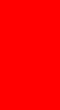

In [43]:
#teacher-only
from pytamaro import Color, red, show_graphic

def bar(bar_width: float, value: float, max_value: float, chart_height: float, color: Color) -> Graphic:
    bar_height = value / max_value * chart_height
    return rectangle(bar_width, bar_height, color)

# Show a bar with a width of 60, that would fits into a chart with an overall height of 200, 
# and that represents the value of 5.5 out of 10.0.
show_graphic(bar(60, 5.5, 10.0, 200, red))

### Chart Area
Implement a method to draw the chart area. This should show all the bars required to visualize the given lists of values and colors. The bars should be bottom-aligned, and separated by a gap. The gap should be computed based on the given width of the area, and the number of bars to represent, and the `gap_width_fraction` (gap width as a fraction of bar width).

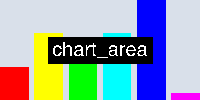

Use the `bar` and `hgap` functions you created above.

Use <API>compose</API> and <API>pin</API> to compose the bars so they are bottom-aligned.

To ensure that you have gaps between bars, but not before or after bars, you may want to use a loop with an index and an if statement to avoid adding the (first or) last gap.

In [ ]:
from pytamaro import (
    Color, Graphic, 
    empty_graphic, compose, pin, bottom_left, bottom_right,
    yellow, green, cyan, blue, magenta
)

def chart_area(values: list[float], colors: list[Color], width: float, height: float) -> Graphic:
    gap_width_fraction = 0.2 # gap width as fraction of bar width
    max_value = # TODO
    bar_count = # TODO
    gap_count = # TODO
    bar_width = # TODO
    gap_width = # TODO
    result = empty_graphic()
    # TODO: loop over values and colors to compose the result
    return result

show_graphic(chart_area([0.5, 1.0, 0.9, 1.0, 1.5, 0.1], [red, yellow, green, cyan, blue, magenta], 200, 100))

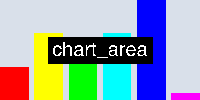

In [82]:
#teacher-only
from pytamaro import (
    Color, Graphic, 
    rectangle, empty_graphic, compose, pin, bottom_left, bottom_right, text, overlay, graphic_width, graphic_height, rgb_color,
    yellow, green, cyan, blue, magenta, white
)

# Not for students: To produce annotated version of the chart
ANNOTATION_AREA_BACKGROUND = rgb_color(217, 224, 234)

def annotation(label: str, font_size: float) -> Graphic:
    t = text(label, "Helvetica", font_size, white)
    return overlay(
        t,
        rectangle(graphic_width(t) + font_size / 2, graphic_height(t) + font_size / 2, black)
    )

def annotate_area(g: Graphic, label: str, font_size: float, annotate: bool) -> Graphic:
    if not annotate:
        return g
    return overlay(
        annotation(label, font_size),
        overlay(
            g,
            rectangle(graphic_width(g), graphic_height(g), ANNOTATION_AREA_BACKGROUND)
        )
    )

def chart_area(values: list[float], colors: list[Color], width: float, height: float, font_size: float, annotate: bool) -> Graphic:
    gap_width_fraction = 0.2 # gap width as fraction of bar width
    max_value = max(values)
    bar_count = len(values)
    gap_count = bar_count - 1
    bar_width = width / (bar_count + gap_width_fraction * gap_count)
    gap_width = 0.2 * bar_width
    result = empty_graphic()
    for i, (value, color) in enumerate(zip(values, colors)):
        b = bar(bar_width, value, max_value, height, color)
        result = compose(pin(bottom_right, result), pin(bottom_left, b))
        if (i < bar_count - 1):
            g = rectangle(gap_width, 0, red)
            result = compose(pin(bottom_right, result), pin(bottom_left, g))
    return annotate_area(result, "chart_area", font_size, annotate)

show_graphic(chart_area([0.5, 1.0, 0.9, 1.0, 1.5, 0.1], [red, yellow, green, cyan, blue, magenta], 200, 100, 20, True))

### X-Axis

Implement a method to draw the `x_axis`.

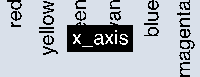

Constructing the `x_axis` is similar to constructing the `chart_area`: you have to compose a sequence of graphics, separated by gaps.
In this case the graphics are the individual labels (implement `x_axis_label` to produce one).
Earch label is a <API>text</API> that is <API>rotate</API>d by 90 degrees
centered on top of a rectangle that has the same width as a bar.

Use the given font size for the texts, and use a font like `"Helvetica"`.

In [ ]:
from pytamaro import overlay, rotate, text, black, top_left, top_right

def x_axis_label(label_width: float, label: str, font_size: float) -> Graphic:
    pass

def x_axis(label_strings: list[str], width: float, font_size: float) -> Graphic:
    pass

show_graphic(x_axis(["red", "yellow", "green", "cyan", "blue", "magenta"], 200, 20))

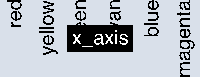

In [83]:
#teacher-only
from pytamaro import overlay, rotate, text, black, top_left, top_right

def x_axis_label(label_width: float, label: str, font_size: float) -> Graphic:
    return overlay(
        rotate(90, text(label, "Helvetica", font_size, black)),
        hgap(label_width)
    )

def x_axis(label_strings: list[str], width: float, font_size: float, annotate: bool) -> Graphic:
    gap_width_fraction = 0.2 # gap width as fraction of bar width
    label_count = len(label_strings)
    gap_count = label_count - 1
    label_width = width / (label_count + gap_width_fraction * gap_count)
    gap_width = 0.2 * label_width
    result = empty_graphic()
    for i, label in enumerate(label_strings):
        b = x_axis_label(label_width, label, font_size)
        result = compose(pin(top_right, result), pin(top_left, b))
        if (i < label_count - 1):
            g = hgap(gap_width)
            result = compose(pin(top_right, result), pin(top_left, g))
    return annotate_area(result, "x_axis", font_size, annotate)


show_graphic(x_axis(["red", "yellow", "green", "cyan", "blue", "magenta"], 200, 20, True))

### Y-Axis

Implement a method to draw the `y_axis`.

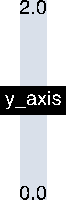

Use the given font size for the texts.

In [47]:
def y_axis(values: list[float], height: float, font_size: float) -> Graphic:
    pass

show_graphic(y_axis([1.0, 2.0, 0.5], 200, 20))

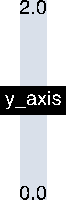

In [84]:
#teacher-only
def y_axis(values: list[float], height: float, font_size: float, annotate: bool) -> Graphic:
    return annotate_area(
        compose(
            pin(bottom_right, text(str(0.0), "Helvetica", font_size, black)),
            pin(bottom_right, 
                compose(
                    pin(top_right, text(str(max(values)), "Helvetica", font_size, black)),
                    pin(top_right, vgap(height))
                )
            )
        ),
        "y_axis",
        font_size,
        annotate
    )

show_graphic(y_axis([1.0, 2.0, 0.5], 200, 20, True))

### A Complete Bar Chart

Given the `chart_area`, `x_axis`, and `y_axis` functions, we are now ready to create a complete bar chart.

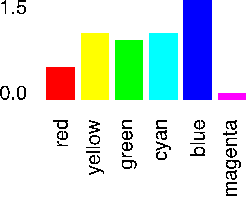

Our `bar_chart` function receives a list of values, colors, and labels, the desired overall width and height of the chart, and the desired font size.

In [ ]:
def bar_chart(values: list[float], colors: list[Color], labels: list[str], width: float, height: float, font_size: float) -> Graphic:
    pass

show_graphic(
    bar_chart(
        [0.5, 1.0, 0.9, 1.0, 1.5, 0.1],
        [red, yellow, green, cyan, blue, magenta],
        ["red", "yellow", "green", "cyan", "blue", "magenta"],
        200, 100, 20
    )
)

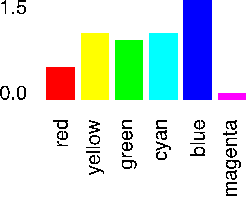

In [86]:
#teacher-only
from pytamaro import beside, above

# the annotate parameter is for generating the chart structure image (not part of what students need to generage)
def bar_chart(values: list[float], colors: list[Color], labels: list[str], width: float, height: float, font_size: float, annotate: bool) -> Graphic:
    return compose(
        pin(top_right,
            beside(
                y_axis(values, height, font_size, annotate),
                hgap(font_size)
            )
        ),
        pin(top_left,
            above(
                chart_area(values, colors, width, height, font_size, annotate),
                above(
                    vgap(font_size),
                    x_axis(labels, width, font_size, annotate)
                )
            )
        )
    )

show_graphic(
    bar_chart(
        [0.5, 1.0, 0.9, 1.0, 1.5, 0.1],
        [red, yellow, green, cyan, blue, magenta],
        ["red", "yellow", "green", "cyan", "blue", "magenta"],
        200, 100, 20, False
    )
)


In [79]:
#teacher-only
from pytamaro import save_graphic

save_graphic(
    "labeled-color-bar-chart.svg",
    bar_chart(
        [0.5, 1.0, 0.9, 1.0, 1.5, 0.1],
        [red, yellow, green, cyan, blue, magenta],
        ["red", "yellow", "green", "cyan", "blue", "magenta"],
        200, 100, 20, False
    )
)

save_graphic(
    "labeled-color-bar-chart-annotated.svg",
    bar_chart(
        [0.5, 1.0, 0.9, 1.0, 1.5, 0.1],
        [red, yellow, green, cyan, blue, magenta],
        ["red", "yellow", "green", "cyan", "blue", "magenta"],
        200, 100, 20, True
    )
)

### Lugano's Neighborhoods

Here is data about the nighborhoods of the city of Lugano.
We first design a dataclass to represent a neighborhood.
Then we create a list of all neighborhoods.

In [26]:
from dataclasses import dataclass
from math import nan

@dataclass
class Neighborhood:
    name: str
    population: int
    area: float
    minElevation: float
    maxElevation: float

lugano_neighborhoods = [
    Neighborhood("Barbengo", 2351, 2.62, 370.0, 475.0),
    Neighborhood("Besso", 5193, 0.65, nan, nan),
    Neighborhood("Brè-Aldesago", 1072, 4.2, nan, nan),
    Neighborhood("Breganzona", 5364, 2.28, 435, 515),
    Neighborhood("Cadro", 2740, 4.56, 475, 1516),
    Neighborhood("Carabbia", 615, 1.07, 518, 588),
    Neighborhood("Carona", 949, 4.69, 602, 911),
    Neighborhood("Castagnola-Cassarate-Ruvigliana", 6424, 1.43, nan, nan),
    Neighborhood("Centro", 5404, 1.03, nan, nan),
    Neighborhood("Cureggia", 178, 0.66, 653, 1180),
    Neighborhood("Davesco-Soragno", 1595, 2.5, 421, 1517),
    Neighborhood("Gandria", 285, 3.45, 292, 1034),
    Neighborhood("Loreto", 3080, 0.59, nan, nan),
    Neighborhood("Molino Nuovo", 9662, 1.23, nan, nan),
    Neighborhood("Pambio-Noranco", 803, 0.55, 349, 376),
    Neighborhood("Pazzallo", 1666, 1.62, 423, 856),
    Neighborhood("Pregassona", 9400, 2.26, 378, 1250),
    Neighborhood("Sonvico", 2098, 11.06, 603, 1491),
    Neighborhood("Val Colla", 1340, 11.06, 1100, 2116),
    Neighborhood("Viganello", 7021, 1.2, 283, 283),
    Neighborhood("Villa Luganese", 557, 2.21, 603, 1350),
]

### Visualizing a List of Objects

Let's create a function that allows us to more easily create a bar chart
if we have a list of objects that represent the items we want to visualize.

In [32]:

from typing import Callable

def bar_chart_from_objects(
    objects: list,
    values: Callable,
    colors: Callable,
    labels: Callable,
    width: float, height: float, font_size: float
) -> Graphic:
    return bar_chart(
        [values(o) for o in objects],
        [colors(o) for o in objects],
        [labels(o) for o in objects],
        width, height, font_size
    )


#### Neighborhood Populations

Let's show the population of each neigbhorhood, sorting the neighborhoods in ascending order by population.

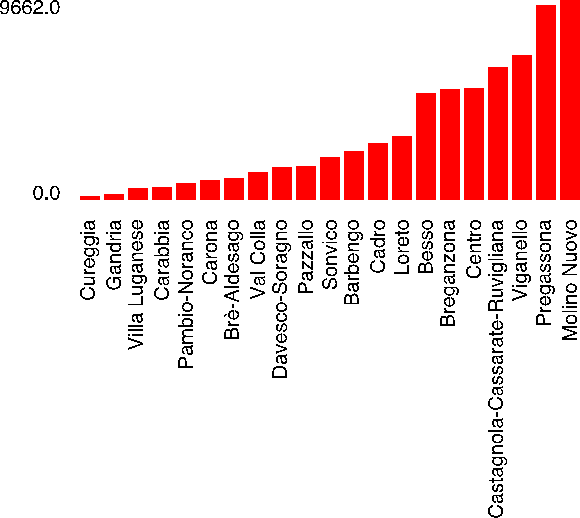

In [34]:
show_graphic(
    bar_chart_from_objects(
        sorted(lugano_neighborhoods, key=lambda n: n.population),
        lambda n: float(n.population),
        lambda n: red,
        lambda n: n.name,
        500, 200, 20
    )
)


### Population Density

Show the neighborhoods by population density,
with the bar height corresponding to population density,
and the bar color saturation corresponding to population

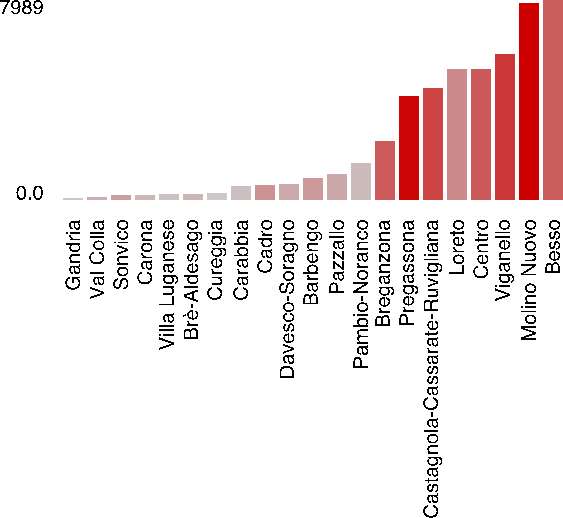

In [40]:
from pytamaro import hsv_color

show_graphic(
    bar_chart_from_objects(
        sorted(lugano_neighborhoods, key=lambda n: n.population / n.area),
        lambda n: int(n.population / n.area),
        lambda n: hsv_color(0, n.population / max(n.population for n in lugano_neighborhoods), 0.8),
        lambda n: n.name,
        500, 200, 20
    )
)

In [41]:
#teacher-only
from pytamaro import hsv_color

save_graphic(
    "pop-density.svg",
    bar_chart_from_objects(
        sorted(lugano_neighborhoods, key=lambda n: n.population / n.area),
        lambda n: int(n.population / n.area),
        lambda n: hsv_color(0, n.population / max(n.population for n in lugano_neighborhoods), 0.8),
        lambda n: n.name,
        500, 200, 20
    )
)

#### More...

Explore the dataset further, for example by visualizing the elevation differences for each neigborhood.